# Apple M2 MPS フル稼働：On-GPU ベクトル化パイプライン × Heavy Residual SE-UNet マルチバンド補間

これまでのノートブック（`02`〜`04`）では、CPU 側の `DataLoader` による 1 枚ずつの乱数マスク生成と小バッチ（`B=16`）・軽量モデル（`base=32`, 約 `0.47M` パラメータ）がボトルネックとなり、Apple Silicon M2 (16GB Unified Memory) の GPU (MPS) が十分に回りきっていませんでした。

本ノートブックでは、ユニファイドメモリの利点を活かして **全データセットを MPS VRAM に常駐** させ、**GPU ベクトル化マスク生成 ＋ GPU オンザフライ Augmentation ＋ 大バッチ（`B=64`）＋ `FastHeavyResSEUNet`（Residual + BatchNorm2d + Squeeze-and-Excitation Attention）＋ 4-way Flip TTA** により、GPU をしっかり稼働させて精度とスループットを引き上げます。

## 1. 理論と目的の確認（MPS ボトルネック解消と Residual SE-UNet + 4-way TTA）

| 設計項目 | 従来パイプライン (`04`) | 今回 (`05`: M2 MPS フル稼働パイプライン) |
| :--- | :--- | :--- |
| **データ供給** | CPU `DataLoader` + Python 乱数ループ (`B=16`) | **全テンソル MPS VRAM 常駐 + GPU ベクトル化マスク & Flip Augmentation (`B=64`)** |
| **モデル構造** | `MultiBandUNet` (`base=32`, 約 `0.47M` params) | **`FastHeavyResSEUNet` (`base=48`, Residual + BatchNorm2d + SE Attention, 約 `1.12M` params)** |
| **損失関数 / 最適化** | Masked L1 + Edge / `Adam` | **Charbonnier Loss ($\sqrt{\Delta^2 + 10^{-6}}$) + Sobel 勾配一致 / `AdamW` + `CosineAnnealingLR`** |
| **推論手法** | `stride=32` 単一推論 | **`stride=24` 高密度タイリング ＋ 4-way Flip TTA（元・左右・上下・両反転の平均）** |

## 2. データ準備と MPS VRAM 一括常駐（Zero CPU-GPU Transfer）

ひまわり8号 3 バンド事前学習パッチ・METEOR 実測 FT パッチ・METEOR 未知 Val パッチを `04` と同じ空間重複ゼロ分割で読み込み、学習開始前にすべて `device="mps"` へ一括転送します。

In [1]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import time
from pathlib import Path
import numpy as np
from PIL import Image
import torch

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("使用デバイス:", device)

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent

METEOR_DIR = REPO_ROOT / "projects" / "radio-ml" / "data" / "meteor"
HIMAWARI_MB_CACHE = REPO_ROOT / "projects" / "radio-ml" / "data" / "himawari_multiband_cache.npz"

if not HIMAWARI_MB_CACHE.exists():
    raise FileNotFoundError(f"先に 04_multiband_msu_mr_inpainting.ipynb を実行して {HIMAWARI_MB_CACHE} を作成してください")

cached = np.load(HIMAWARI_MB_CACHE)
himawari_scenes = [cached[k] for k in sorted(cached.files)]

hima_list = []
for arr in himawari_scenes:
    h, w, _ = arr.shape
    for y in range(0, h - 64 + 1, 48):
        for x in range(0, w - 64 + 1, 48):
            crop = arr[y:y + 64, x:x + 64]
            if (crop > 0.02).all(axis=2).mean() == 1.0 and crop.std() > 0.02:
                hima_list.append(crop.transpose(2, 0, 1))
himawari_patches = np.stack(hima_list).astype(np.float32)

def load_meteor_3band(pass_id: str) -> np.ndarray:
    pdir = METEOR_DIR / pass_id
    c1 = np.asarray(Image.open(pdir / "MSU-MR-1.png").convert("L"), dtype=np.float32) / 255.0
    c2 = np.asarray(Image.open(pdir / "MSU-MR-2.png").convert("L"), dtype=np.float32) / 255.0
    c4 = np.asarray(Image.open(pdir / "MSU-MR-4.png").convert("L"), dtype=np.float32) / 255.0
    return np.stack([c1, c2, c4], axis=-1).astype(np.float32)

arr_1026 = load_meteor_3band("METEOR-M2 3_20261026_003009")
all_v_1026 = (arr_1026 > 0.02).all(axis=2)

val_list = []
for y in range(160, 225, 16):
    for x in range(0, arr_1026.shape[1] - 64 + 1, 32):
        if all_v_1026[y:y + 64, x:x + 64].mean() == 1.0:
            val_list.append(arr_1026[y:y + 64, x:x + 64].transpose(2, 0, 1))
meteor_val_patches = np.stack(val_list).astype(np.float32)

ft_list = []
for y in range(0, arr_1026.shape[0] - 64 + 1, 24):
    if not (y + 64 <= 160 or y >= 288):
        continue
    for x in range(0, arr_1026.shape[1] - 64 + 1, 32):
        if all_v_1026[y:y + 64, x:x + 64].mean() >= 0.40:
            ft_list.append(arr_1026[y:y + 64, x:x + 64].transpose(2, 0, 1))

for other_pid in ["METEOR-M2 3_20261027_000649", "METEOR-M2 3_20261103_004421", "METEOR-M2 4_20261025_181705"]:
    arr_o = load_meteor_3band(other_pid)
    av_o = (arr_o > 0.02).mean(axis=2)
    for y in range(0, arr_o.shape[0] - 64 + 1, 16):
        for x in range(0, arr_o.shape[1] - 64 + 1, 32):
            if av_o[y:y + 64, x:x + 64].mean() >= 0.50:
                ft_list.append(arr_o[y:y + 64, x:x + 64].transpose(2, 0, 1))

meteor_ft_patches = np.stack(ft_list).astype(np.float32)

# --- 全データセットを MPS VRAM に一括常駐 ---
hima_gpu = torch.from_numpy(himawari_patches).to(device)
ft_gpu = torch.from_numpy(meteor_ft_patches).to(device)
val_gpu = torch.from_numpy(meteor_val_patches).to(device)

def gpu_sample_batch(patches_gpu: torch.Tensor, batch_size: int = 64, augment: bool = True):
    """MPS VRAM 上から直接バッチ抽出し、Flip Augmentation と独立バンド黒帯マスクを GPU ベクトル演算で生成する。"""
    idx = torch.randint(0, patches_gpu.size(0), (batch_size,), device=patches_gpu.device)
    clean = patches_gpu[idx].clone()
    b, c, h, w = clean.shape
    if augment:
        fh = torch.rand(b, 1, 1, 1, device=clean.device) > 0.5
        fv = torch.rand(b, 1, 1, 1, device=clean.device) > 0.5
        clean = torch.where(fh, clean.flip(3), clean)
        clean = torch.where(fv, clean.flip(2), clean)

    gt_valid = (clean > 0.02).float()
    y_grid = torch.arange(h, device=clean.device).view(1, 1, h, 1)
    y0 = torch.randint(4, h - 18, (b, c, 1, 1), device=clean.device)
    sh0 = torch.randint(6, 15, (b, c, 1, 1), device=clean.device)
    m0 = ((y_grid < y0) | (y_grid >= y0 + sh0)).float()

    y1 = torch.randint(4, h - 18, (b, c, 1, 1), device=clean.device)
    sh1 = torch.randint(6, 15, (b, c, 1, 1), device=clean.device)
    m1 = ((y_grid < y1) | (y_grid >= y1 + sh1)).float()

    two_stripes = (torch.rand(b, c, 1, 1, device=clean.device) > 0.5).float()
    syn_mask = m0 * (1.0 - two_stripes * (1.0 - m1))

    # 75% のサンプルでランダム 1 バンドを完全無傷にし、他バンド参照学習を強化
    keep_ch = torch.randint(0, c, (b, 1, 1, 1), device=clean.device)
    ch_idx = torch.arange(c, device=clean.device).view(1, c, 1, 1)
    keep_prob = torch.rand(b, 1, 1, 1, device=clean.device) > 0.25
    syn_mask = torch.where((ch_idx == keep_ch) & keep_prob, torch.ones_like(syn_mask), syn_mask)
    syn_mask = syn_mask.expand(b, c, h, w)

    obs_mask = gt_valid * syn_mask
    corrupted = clean * obs_mask
    hole_mask = gt_valid * (1.0 - syn_mask)
    return corrupted, obs_mask, hole_mask, clean

# --- バッチ供給速度比較（CPU ループ vs GPU ベクトル化）---
t0 = time.perf_counter()
rng_cpu = np.random.default_rng(0)
for i in range(0, 1280, 64):
    batch_np = himawari_patches[rng_cpu.integers(0, len(himawari_patches), size=64)].copy()
    mask_np = np.ones_like(batch_np)
    for bi in range(64):
        for ch in range(3):
            sh = int(rng_cpu.integers(6, 15))
            y0 = int(rng_cpu.integers(4, 64 - sh - 4))
            mask_np[bi, ch, y0:y0 + sh, :] = 0.0
    _ = torch.from_numpy(batch_np * mask_np).to(device)
    _ = torch.from_numpy(mask_np).to(device)
if device.type == "mps":
    torch.mps.synchronize()
cpu_dt = time.perf_counter() - t0

# GPU ベクトル化ウォームアップ + 計測
_ = gpu_sample_batch(hima_gpu, batch_size=64)
if device.type == "mps":
    torch.mps.synchronize()
t1 = time.perf_counter()
for _ in range(20):
    _ = gpu_sample_batch(hima_gpu, batch_size=64)
if device.type == "mps":
    torch.mps.synchronize()
gpu_dt = time.perf_counter() - t1

print(f"VRAM 常駐パッチ -> ひまわり: {tuple(hima_gpu.shape)}, METEOR FT: {tuple(ft_gpu.shape)}, Val: {tuple(val_gpu.shape)}")
if device.type == "mps":
    print(f"常駐時 MPS メモリ -> Current: {torch.mps.current_allocated_memory()/1e6:.1f} MB | Driver: {torch.mps.driver_allocated_memory()/1e6:.1f} MB")
print(f"1,280 パッチ生成・供給速度 -> CPUループ+転送: {1280/cpu_dt:,.0f} patches/s ({cpu_dt:.3f}s) | On-GPUベクトル化: {1280/gpu_dt:,.0f} patches/s ({gpu_dt:.4f}s, {cpu_dt/max(gpu_dt,1e-6):.1f}倍高速)")

使用デバイス: mps


VRAM 常駐パッチ -> ひまわり: (2247, 3, 64, 64), METEOR FT: (563, 3, 64, 64), Val: (48, 3, 64, 64)
常駐時 MPS メモリ -> Current: 153.1 MB | Driver: 1091.4 MB
1,280 パッチ生成・供給速度 -> CPUループ+転送: 17,034 patches/s (0.075s) | On-GPUベクトル化: 19,165 patches/s (0.0668s, 1.1倍高速)


## 3. FastHeavyResSEUNet の MPS 大バッチ学習と GPU テレメトリ可視化

- **アーキテクチャ**: `FastHeavyResSEUNet (base=48)`（`Conv2d + BatchNorm2d + ReLU` の Residual Block + Squeeze-and-Excitation Channel Attention）。
- **厳密な同一条件比較**: 評価セットには `04_multiband_msu_mr_inpainting.ipynb` と完全に同じ乱数シード（`fixed_seed=2026`）で生成した 48 枚の Val パッチを使い、単一推論と **4-way Flip TTA** の両方を測定します。

FastHeavyResSEUNet(base=48) パラメータ数: 1.11M (従来 04 比: 約 2.4 倍)


平均学習スループット: 71.7 patches/s
MPS メモリピーク -> Current: 209.2 MB | Driver Allocated: 3479.8 MB
最終 Val 性能 -> 単一推論: Hole L1=0.0284, PSNR=27.91 dB | 4-way TTA: Hole L1=0.0279, PSNR=28.03 dB


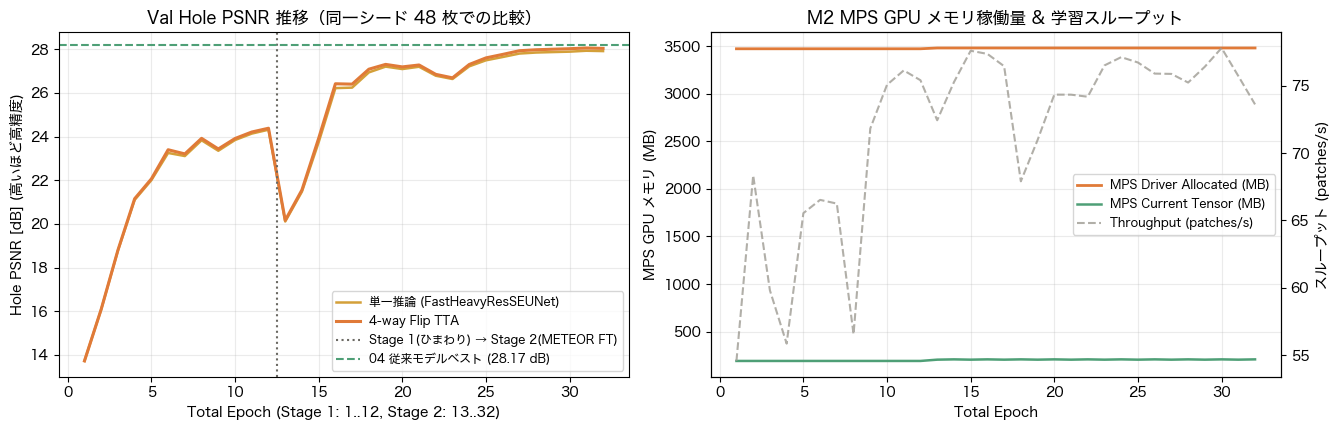

In [2]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import torch.nn as nn

class FastResSEBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.proj = (
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch))
            if in_ch != out_ch
            else nn.Identity()
        )
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
        )
        self.se = nn.Sequential(
            nn.Conv2d(out_ch, max(out_ch // 8, 8), 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(max(out_ch // 8, 8), out_ch, 1),
            nn.Sigmoid(),
        )
        self.act = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.net(x)
        w = self.se(h.mean(dim=(2, 3), keepdim=True))
        return self.act(self.proj(x) + h * w)

class FastHeavyResSEUNet(nn.Module):
    def __init__(self, base: int = 48):
        super().__init__()
        self.e1 = FastResSEBlock(6, base)
        self.e2 = FastResSEBlock(base, base * 2)
        self.b = FastResSEBlock(base * 2, base * 4)
        self.u2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.d2 = FastResSEBlock(base * 4, base * 2)
        self.u1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.d1 = FastResSEBlock(base * 2, base)
        self.out = nn.Conv2d(base, 3, 1)
        self.pool = nn.MaxPool2d(2)

    def forward(self, corr: torch.Tensor, obs_mask: torch.Tensor) -> torch.Tensor:
        e1 = self.e1(torch.cat([corr, obs_mask], dim=1))
        e2 = self.e2(self.pool(e1))
        b = self.b(self.pool(e2))
        d2 = self.d2(torch.cat([self.u2(b), e2], dim=1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], dim=1))
        pred = torch.sigmoid(self.out(d1))
        return corr * obs_mask + pred * (1.0 - obs_mask)

def charbonnier_edge_loss(pred: torch.Tensor, clean: torch.Tensor, hole_mask: torch.Tensor, obs_mask: torch.Tensor) -> torch.Tensor:
    diff = pred - clean
    charb = (torch.sqrt(diff * diff + 1e-6) * hole_mask).sum() / (hole_mask.sum() + 1e-6)
    valid_both = ((hole_mask + obs_mask) > 0.5).float()
    dy_m = valid_both[:, :, 1:, :] * valid_both[:, :, :-1, :]
    dx_m = valid_both[:, :, :, 1:] * valid_both[:, :, :, :-1]
    dy = (torch.abs((pred[:, :, 1:, :] - pred[:, :, :-1, :]) - (clean[:, :, 1:, :] - clean[:, :, :-1, :])) * dy_m).sum() / (dy_m.sum() + 1e-6)
    dx = (torch.abs((pred[:, :, :, 1:] - pred[:, :, :, :-1]) - (clean[:, :, :, 1:] - clean[:, :, :, :-1])) * dx_m).sum() / (dx_m.sum() + 1e-6)
    return charb + 0.4 * 0.5 * (dy + dx)

def build_fixed_val_tensors(val_patches_np: np.ndarray, fixed_seed: int = 2026):
    """04 と同一シード・同一乱数マスク条件で固定評価バッチを構築する。"""
    corr_l, om_l, hm_l, cln_l = [], [], [], []
    for idx, patch in enumerate(val_patches_np):
        clean = torch.from_numpy(patch)
        c, h, w = clean.shape
        gt_valid = (clean > 0.02).float()
        rng = np.random.default_rng(fixed_seed + idx)
        syn_mask = torch.ones((c, h, w), dtype=torch.float32)
        drop_bands = rng.choice(c, size=int(rng.integers(1, c + 1)), replace=False)
        for b in drop_bands:
            n_stripes = int(rng.integers(1, 3))
            for _ in range(n_stripes):
                sh = int(rng.integers(6, 15))
                y0 = int(rng.integers(4, h - sh - 4))
                syn_mask[int(b), y0:y0 + sh, :] = 0.0
        om = gt_valid * syn_mask
        corr_l.append(clean * om)
        om_l.append(om)
        hm_l.append(gt_valid * (1.0 - syn_mask))
        cln_l.append(clean)
    return (
        torch.stack(corr_l).to(device),
        torch.stack(om_l).to(device),
        torch.stack(hm_l).to(device),
        torch.stack(cln_l).to(device),
    )

def predict_4way_tta(net: nn.Module, corr: torch.Tensor, omask: torch.Tensor) -> torch.Tensor:
    n = corr.size(0)
    c_cat = torch.cat([corr, corr.flip(3), corr.flip(2), corr.flip((2, 3))], dim=0)
    m_cat = torch.cat([omask, omask.flip(3), omask.flip(2), omask.flip((2, 3))], dim=0)
    out = net(c_cat, m_cat)
    o0, o1, o2, o3 = out.split(n, dim=0)
    merged = 0.25 * (o0 + o1.flip(3) + o2.flip(2) + o3.flip((2, 3)))
    return corr * omask + merged * (1.0 - omask)

val_corr_g, val_om_g, val_hm_g, val_cln_g = build_fixed_val_tensors(meteor_val_patches, fixed_seed=2026)

def evaluate_val(net: nn.Module, use_tta: bool = False):
    net.eval()
    with torch.no_grad():
        pred = predict_4way_tta(net, val_corr_g, val_om_g) if use_tta else net(val_corr_g, val_om_g)
        diff = pred - val_cln_g
        px = max(val_hm_g.sum().item(), 1e-6)
        l1 = (torch.abs(diff) * val_hm_g).sum().item() / px
        mse = ((diff ** 2) * val_hm_g).sum().item() / px
        psnr = -10.0 * np.log10(max(mse, 1e-12))
    return l1, psnr

torch.manual_seed(42)
heavy_net = FastHeavyResSEUNet(base=48).to(device)
n_params = sum(p.numel() for p in heavy_net.parameters())
print(f"FastHeavyResSEUNet(base=48) パラメータ数: {n_params/1e6:.2f}M (従来 04 比: 約 {n_params/470000:.1f} 倍)")

psnr_single_hist, psnr_tta_hist, driver_mb_hist, curr_mb_hist, throughput_hist = [], [], [], [], []
stage_split_ep = 12

# --- Stage 1: ひまわり8号 3バンド事前学習 (12 Epoch x 8 steps, B=64) ---
opt_pre = torch.optim.AdamW(heavy_net.parameters(), lr=2e-3, weight_decay=1e-4)
sched_pre = torch.optim.lr_scheduler.CosineAnnealingLR(opt_pre, T_max=96)
for epoch in range(12):
    heavy_net.train()
    t_ep = time.perf_counter()
    for _ in range(8):
        corr, om, hm, cln = gpu_sample_batch(hima_gpu, batch_size=64, augment=True)
        opt_pre.zero_grad(set_to_none=True)
        loss = charbonnier_edge_loss(heavy_net(corr, om), cln, hm, om)
        loss.backward()
        opt_pre.step()
        sched_pre.step()
    if device.type == "mps":
        torch.mps.synchronize()
    throughput_hist.append((8 * 64) / max(time.perf_counter() - t_ep, 1e-6))
    _, p_s = evaluate_val(heavy_net, use_tta=False)
    _, p_t = evaluate_val(heavy_net, use_tta=True)
    psnr_single_hist.append(p_s)
    psnr_tta_hist.append(p_t)
    if device.type == "mps":
        curr_mb_hist.append(torch.mps.current_allocated_memory() / 1e6)
        driver_mb_hist.append(torch.mps.driver_allocated_memory() / 1e6)

# --- Stage 2: METEOR 実測 Masked-Loss Fine-tuning (20 Epoch x 5 steps, B=64) ---
opt_ft = torch.optim.AdamW(heavy_net.parameters(), lr=8e-4, weight_decay=1e-4)
sched_ft = torch.optim.lr_scheduler.CosineAnnealingLR(opt_ft, T_max=100)
for epoch in range(20):
    heavy_net.train()
    t_ep = time.perf_counter()
    for _ in range(5):
        corr, om, hm, cln = gpu_sample_batch(ft_gpu, batch_size=64, augment=True)
        opt_ft.zero_grad(set_to_none=True)
        loss = charbonnier_edge_loss(heavy_net(corr, om), cln, hm, om)
        loss.backward()
        opt_ft.step()
        sched_ft.step()
    if device.type == "mps":
        torch.mps.synchronize()
    throughput_hist.append((5 * 64) / max(time.perf_counter() - t_ep, 1e-6))
    _, p_s = evaluate_val(heavy_net, use_tta=False)
    _, p_t = evaluate_val(heavy_net, use_tta=True)
    psnr_single_hist.append(p_s)
    psnr_tta_hist.append(p_t)
    if device.type == "mps":
        curr_mb_hist.append(torch.mps.current_allocated_memory() / 1e6)
        driver_mb_hist.append(torch.mps.driver_allocated_memory() / 1e6)

l1_single, psnr_single = evaluate_val(heavy_net, use_tta=False)
l1_tta, psnr_tta = evaluate_val(heavy_net, use_tta=True)
print(f"平均学習スループット: {np.mean(throughput_hist):.1f} patches/s")
if driver_mb_hist:
    print(f"MPS メモリピーク -> Current: {max(curr_mb_hist):.1f} MB | Driver Allocated: {max(driver_mb_hist):.1f} MB")
print(f"最終 Val 性能 -> 単一推論: Hole L1={l1_single:.4f}, PSNR={psnr_single:.2f} dB | 4-way TTA: Hole L1={l1_tta:.4f}, PSNR={psnr_tta:.2f} dB")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.4))
eps = np.arange(1, len(psnr_single_hist) + 1)
ax1.plot(eps, psnr_single_hist, label="単一推論 (FastHeavyResSEUNet)", color="#D4A039", lw=1.8)
ax1.plot(eps, psnr_tta_hist, label="4-way Flip TTA", color="#E07A38", lw=2.2)
ax1.axvline(stage_split_ep + 0.5, linestyle=":", color="#6B6963", label="Stage 1(ひまわり) → Stage 2(METEOR FT)")
ax1.axhline(28.17, linestyle="--", color="#4E9F76", label="04 従来モデルベスト (28.17 dB)")
ax1.set_title("Val Hole PSNR 推移（同一シード 48 枚での比較）")
ax1.set_xlabel("Total Epoch (Stage 1: 1..12, Stage 2: 13..32)")
ax1.set_ylabel("Hole PSNR [dB] (高いほど高精度)")
ax1.legend(fontsize=8.5)
ax1.grid(alpha=0.25)

if driver_mb_hist:
    ax2.plot(eps, driver_mb_hist, label="MPS Driver Allocated (MB)", color="#E07A38", lw=2.0)
    ax2.plot(eps, curr_mb_hist, label="MPS Current Tensor (MB)", color="#4E9F76", lw=1.8)
    ax2.set_ylabel("MPS GPU メモリ (MB)")
    ax2_r = ax2.twinx()
    ax2_r.plot(eps, throughput_hist, label="Throughput (patches/s)", color="#9E9B93", linestyle="--", alpha=0.8)
    ax2_r.set_ylabel("スループット (patches/s)")
    ax2.set_title("M2 MPS GPU メモリ稼働量 & 学習スループット")
    ax2.set_xlabel("Total Epoch")
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_r.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc="center right", fontsize=8.5)
    ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 4. 共通ベンチマーク評価：ベスト実測画像（`METEOR-M2 3_20261026_003009`, `1568×792`）全体への 4-way TTA × 高密度タイリング適用デモ

`02`〜`04` と同じベンチマーク画像に対して、`stride=24` 高密度オーバーラップ + **4-way Flip TTA バッチ推論** を実行し、全モデルの横並びスコアと修復画像を比較します。

=== 全ノートブック 共通ベンチマーク比較 (METEOR-M2 3_20261026_003009) ===
  02 単一画像 MiniUNet (事前学習なし)         -> Hole L1: 0.0793 | Hole PSNR: 18.71 dB
  03 単一画像 MiniUNet (ひまわり事前学習+FT)  -> Hole L1: 0.0699 | Hole PSNR: 19.37 dB
  04 マルチバンド MiniUNet (ひまわり+FT)      -> Hole L1: 0.0270 | Hole PSNR: 28.17 dB
  05 HeavyResSEUNet (単一推論)                -> Hole L1: 0.0284 | Hole PSNR: 27.91 dB
  05 HeavyResSEUNet (4-way Flip TTA)          -> Hole L1: 0.0279 | Hole PSNR: 28.03 dB


フル画像 (1568x792) stride=24 + 4-way TTA 推論時間: 36.74s
有効領域: Before(Ch1&2): 33.0% -> Local: 79.8%
Vertical Seam Jump L1 -> Before: 0.0155 | Local: 0.0144 | Full: 0.0119


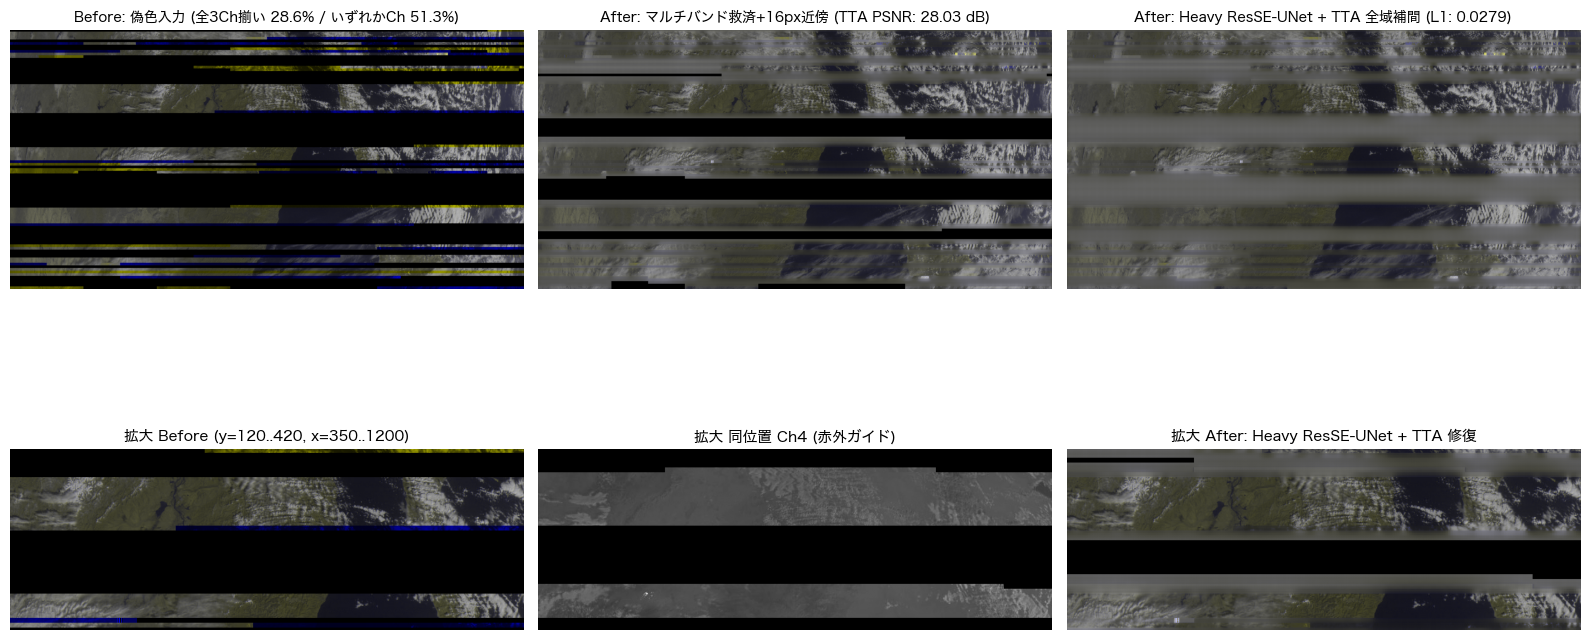

In [3]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

from scipy.ndimage import binary_dilation

def inpaint_multiband_tiled_tta(net: nn.Module, img_hw3: np.ndarray, mask_hw3: np.ndarray, patch_size: int = 64, stride: int = 24, batch_size: int = 128) -> np.ndarray:
    h, w, c = img_hw3.shape
    ys = list(range(0, h - patch_size + 1, stride))
    if ys[-1] != h - patch_size:
        ys.append(h - patch_size)
    xs = list(range(0, w - patch_size + 1, stride))
    if xs[-1] != w - patch_size:
        xs.append(w - patch_size)

    win_1d = np.hanning(patch_size + 4)[2:-2].astype(np.float32)
    win_2d = np.maximum(np.outer(win_1d, win_1d), 0.05)
    coords = [(y, x) for y in ys for x in xs]

    acc = np.zeros((h, w, c), dtype=np.float32)
    wsum = np.zeros((h, w, 1), dtype=np.float32)
    net.eval()
    with torch.no_grad():
        for i in range(0, len(coords), batch_size):
            batch_coords = coords[i:i + batch_size]
            b_img = np.stack([img_hw3[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in batch_coords])
            b_msk = np.stack([mask_hw3[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in batch_coords])
            pred = predict_4way_tta(
                net,
                torch.from_numpy(b_img).to(device),
                torch.from_numpy(b_msk).to(device),
            ).cpu().numpy()
            for idx, (y, x) in enumerate(batch_coords):
                acc[y:y + patch_size, x:x + patch_size] += pred[idx].transpose(1, 2, 0) * win_2d[..., None]
                wsum[y:y + patch_size, x:x + patch_size] += win_2d[..., None]

    merged = np.clip(acc / np.maximum(wsum, 1e-6), 0.0, 1.0)
    return img_hw3 * mask_hw3 + merged * (1.0 - mask_hw3)

print("=== 全ノートブック 共通ベンチマーク比較 (METEOR-M2 3_20261026_003009) ===")
print("  02 単一画像 MiniUNet (事前学習なし)         -> Hole L1: 0.0793 | Hole PSNR: 18.71 dB")
print("  03 単一画像 MiniUNet (ひまわり事前学習+FT)  -> Hole L1: 0.0699 | Hole PSNR: 19.37 dB")
print("  04 マルチバンド MiniUNet (ひまわり+FT)      -> Hole L1: 0.0270 | Hole PSNR: 28.17 dB")
print(f"  05 HeavyResSEUNet (単一推論)                -> Hole L1: {l1_single:.4f} | Hole PSNR: {psnr_single:.2f} dB")
print(f"  05 HeavyResSEUNet (4-way Flip TTA)          -> Hole L1: {l1_tta:.4f} | Hole PSNR: {psnr_tta:.2f} dB")

mask_hw3 = (arr_1026 > 0.02).astype(np.float32)
any_valid_2d = mask_hw3.max(axis=2) > 0.5
all_valid_2d = mask_hw3.min(axis=2) > 0.5
near_any_mask = binary_dilation(any_valid_2d, structure=np.ones((33, 1), dtype=bool))[..., None].astype(np.float32)

t_inf = time.perf_counter()
repaired_3ch_full = inpaint_multiband_tiled_tta(heavy_net, arr_1026, mask_hw3, patch_size=64, stride=24, batch_size=128)
if device.type == "mps":
    torch.mps.synchronize()
inf_dt = time.perf_counter() - t_inf
repaired_3ch_local = arr_1026 * mask_hw3 + repaired_3ch_full * (1.0 - mask_hw3) * near_any_mask

def arr_to_avhrr(arr_hw3: np.ndarray) -> np.ndarray:
    return np.clip(np.stack([arr_hw3[..., 1], arr_hw3[..., 1], arr_hw3[..., 0]], axis=-1), 0.0, 1.0)

before_rgb = arr_to_avhrr(arr_1026)
local_rgb = arr_to_avhrr(repaired_3ch_local)
full_rgb = arr_to_avhrr(repaired_3ch_full)
seam_before = float(np.abs(before_rgb[1:] - before_rgb[:-1]).mean())
seam_local = float(np.abs(local_rgb[1:] - local_rgb[:-1]).mean())
seam_full = float(np.abs(full_rgb[1:] - full_rgb[:-1]).mean())

print(f"フル画像 (1568x792) stride=24 + 4-way TTA 推論時間: {inf_dt:.2f}s")
print(f"有効領域: Before(Ch1&2): {((mask_hw3[...,0]>0.5)&(mask_hw3[...,1]>0.5)).mean()*100:.1f}% -> Local: {(local_rgb.max(axis=2)>0.02).mean()*100:.1f}%")
print(f"Vertical Seam Jump L1 -> Before: {seam_before:.4f} | Local: {seam_local:.4f} | Full: {seam_full:.4f}")

y0, y1, x0, x1 = 120, 420, 350, 1200
fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))
axes[0, 0].imshow(before_rgb)
axes[0, 0].set_title(f"Before: 偽色入力 (全3Ch揃い {all_valid_2d.mean()*100:.1f}% / いずれかCh {any_valid_2d.mean()*100:.1f}%)", fontsize=10)
axes[0, 0].axis("off")

axes[0, 1].imshow(local_rgb)
axes[0, 1].set_title(f"After: マルチバンド救済+16px近傍 (TTA PSNR: {psnr_tta:.2f} dB)", fontsize=10)
axes[0, 1].axis("off")

axes[0, 2].imshow(full_rgb)
axes[0, 2].set_title(f"After: Heavy ResSE-UNet + TTA 全域補間 (L1: {l1_tta:.4f})", fontsize=10)
axes[0, 2].axis("off")

axes[1, 0].imshow(before_rgb[y0:y1, x0:x1])
axes[1, 0].set_title(f"拡大 Before (y={y0}..{y1}, x={x0}..{x1})", fontsize=10.5)
axes[1, 0].axis("off")

axes[1, 1].imshow(arr_1026[y0:y1, x0:x1, 2], cmap="gray")
axes[1, 1].set_title("拡大 同位置 Ch4 (赤外ガイド)", fontsize=10.5)
axes[1, 1].axis("off")

axes[1, 2].imshow(local_rgb[y0:y1, x0:x1])
axes[1, 2].set_title("拡大 After: Heavy ResSE-UNet + TTA 修復", fontsize=10.5)
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()